# Generative Adversarials Networks

In [ ]:
import random

import torch
import numpy as np


def same_seeds(seed):
    # Python built-in random module
    random.seed(seed)
    # Numpy
    np.random.seed(seed)
    # Torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

same_seeds(2026)

import os
import glob

import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch import optim
from torch.autograd import Variable
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from qqdm.notebook import qqdm
from torch.nn.utils import spectral_norm

class CrypkoDataset(Dataset):
    def __init__(self,fnames, transform):
        self.fnames = fnames
        self.transform = transform
    def __len__(self):
        return len(self.fnames)
    def __getitem__(self,idx):
        fname = self.fnames[idx]
        img = torchvision.io.read_image(fname)
        img = self.transform(img)
        return img
    
def get_dataset(root):
    fnames = glob.glob(os.path.join(root,  "*.jpg"))
    compose = [
        transforms.ToPILImage(),
        transforms.Resize((64,64)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
    ]
    transform = transforms.Compose(compose)
    dataset = CrypkoDataset(fnames, transform)
    return dataset

def hinge_loss_d(real, fake):
    return F.relu(1.0 - real).mean() + F.relu(1.0 + fake).mean()

def hinge_loss_g(fake):
    return -fake.mean()

dataset = get_dataset("faces")
images = [dataset[i] for i in range(16)]
image = torch.stack(images)
image = image/2 + 0.5
grid = torchvision.utils.make_grid(image, nrow=4)
plt.figure(figsize=(10,10))
plt.imshow(grid.permute(1, 2, 0))
plt.show()

def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class generator(nn.Module): ## generator输入是噪声向量，输出为图像
    def __init__(self,in_dim,dim=64):
        super(generator, self).__init__()
        def deconv_bn_relu(in_dim, out_dim):
            return nn.Sequential(
                nn.ConvTranspose2d(in_dim, out_dim, 4, 2, 1),
                nn.BatchNorm2d(out_dim),
                nn.ReLU(),
                nn.Dropout2d(0.1)
            )
        self.f1 = nn.Sequential(
            nn.Linear(in_dim, dim * 8 * 4 * 4),## 512*4*4
            #nn.BatchNorm1d(dim * 8 * 4 * 4),
            nn.ReLU()
        )
        self.f2 = nn.Sequential(
            deconv_bn_relu(dim * 8, dim * 4),## 8x8x256
            deconv_bn_relu(dim * 4, dim * 2),## 16x16x128
            deconv_bn_relu(dim * 2, dim),## 32x32x64
            nn.ConvTranspose2d(dim, 3, 4, 2, 1),## 64x64x3
            nn.Tanh()
        )
        self.apply(weights_init)
    def forward(self, x):
        out = self.f1(x)
        out = out.view(x.size(0), -1, 4, 4)
        out = self.f2(out)
        return out
       
class discriminator(nn.Module):## discriminator的输入是图像，输出是一个实数，表示输入图像为真的概率
    def __init__(self,in_dim, dim=64):
        super(discriminator, self).__init__()
        def conv_bn_lrelu(in_dim, out_dim):
            return nn.Sequential(
                spectral_norm(nn.Conv2d(in_dim, out_dim, 4, 2, 1)),
                #nn.BatchNorm2d(out_dim),
                nn.LeakyReLU(0.2)
            )
        self.ls = nn.Sequential(
            spectral_norm(nn.Conv2d(in_dim, dim, 4, 2, 1)),## 32x32x64
            nn.LeakyReLU(0.2),
            conv_bn_lrelu(dim, dim * 2),## 16x16x128
            conv_bn_lrelu(dim * 2, dim * 4),## 8x8x256
            conv_bn_lrelu(dim * 4, dim * 8),## 4x4x512
            spectral_norm(nn.Conv2d(dim * 8, 1, 4, 1, 0)) 
        )
        self.apply(weights_init)
    def forward(self, x):
        out = self.ls(x)
        return out.view(-1)


    
batch_size = 64
z_dim = 100
z_sample = Variable(torch.randn(100, z_dim)).cuda()
lr = 1e-4
n_epoch = 50
n_critic = 5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
log_dir = "logs"
os.makedirs(log_dir, exist_ok=True)
ckpt_dir = "ckpt"
os.makedirs(ckpt_dir, exist_ok=True)

G = generator(z_dim).to(device)
D = discriminator(3).to(device)
G.train()
D.train()

criterion = nn.BCELoss()
optimizer_D = optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.999))
optimizer_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0)

steps = 0
for e,epoch in enumerate(range(n_epoch)):
    progress_bar = qqdm(dataloader)
    for i,data in enumerate(progress_bar):
        img = data.to(device)
        bs = img.size(0)
        z = Variable(torch.randn(bs, z_dim)).to(device)
        r_img = Variable(img).to(device)
        f_img = G(z)
        real_label = torch.ones(bs).to(device)
        fake_label = torch.zeros(bs).to(device)
        ## --- discriminator训练 ---
        r_logit = D(r_img.detach())
        f_logit = D(f_img.detach())
        
        
        loss_d = hinge_loss_d(r_logit, f_logit)
        optimizer_D.zero_grad()
        loss_d.backward()
        optimizer_D.step()
        if (steps) % n_critic == 0:
            ## --- generator训练 ---
            z = Variable(torch.randn(bs, z_dim)).to(device)
            f_img = G(z)
            f_logit = D(f_img)
            loss_g = hinge_loss_g(f_logit)
            optimizer_G.zero_grad()
            loss_g.backward()
            optimizer_G.step()
        steps += 1
        progress_bar.set_postfix({
            "d_loss": loss_d.item(),
            "g_loss": loss_g.item(),
            "epoch": epoch,
            "step": steps
        })
    ## --- 每个epoch结束后，保存生成的图像和模型权重 ---
    G.eval()
    f_imgs_sample = (G(z_sample).data + 1) / 2.0
    filename = os.path.join(log_dir, f'Epoch_{epoch+1:03d}.jpg')
    torchvision.utils.save_image(f_imgs_sample, filename, nrow=10)
    print(f' | Save some samples to {filename}.')
    
    # Show generated images in the jupyter notebook.
    grid_img = torchvision.utils.make_grid(f_imgs_sample.cpu(), nrow=10)
    plt.figure(figsize=(10,10))
    plt.imshow(grid_img.permute(1, 2, 0))
    plt.show()
    G.train()

    if (i+1) % 5 == 0 or e == 0:
        # Save the checkpoints.
        torch.save(G.state_dict(), os.path.join(ckpt_dir, 'G.pth'))
        torch.save(D.state_dict(), os.path.join(ckpt_dir, 'D.pth'))

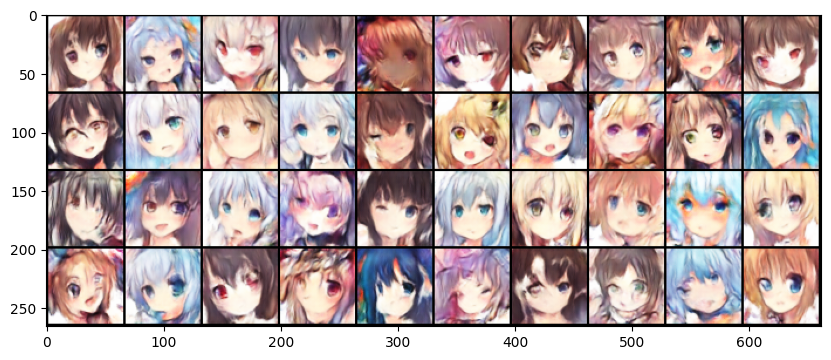

In [3]:
import torch

class generator(nn.Module): ## generator输入是噪声向量，输出为图像
    def __init__(self,in_dim,dim=64):
        super(generator, self).__init__()
        def deconv_bn_relu(in_dim, out_dim):
            return nn.Sequential(
                nn.ConvTranspose2d(in_dim, out_dim, 4, 2, 1),
                nn.BatchNorm2d(out_dim),
                nn.ReLU(),
                nn.Dropout2d(0.1)
            )
        self.f1 = nn.Sequential(
            nn.Linear(in_dim, dim * 8 * 4 * 4),## 512*4*4
            #nn.BatchNorm1d(dim * 8 * 4 * 4),
            nn.ReLU()
        )
        self.f2 = nn.Sequential(
            deconv_bn_relu(dim * 8, dim * 4),## 8x8x256
            deconv_bn_relu(dim * 4, dim * 2),## 16x16x128
            deconv_bn_relu(dim * 2, dim),## 32x32x64
            nn.ConvTranspose2d(dim, 3, 4, 2, 1),## 64x64x3
            nn.Tanh()
        )
        self.apply(weights_init)
    def forward(self, x):
        out = self.f1(x)
        out = out.view(x.size(0), -1, 4, 4)
        out = self.f2(out)
        return out
    
G = generator(z_dim).to(device)
G.load_state_dict(torch.load(os.path.join(ckpt_dir, 'G.pth')))
G.eval()
n_output = 1000
z_sample = Variable(torch.randn(n_output, z_dim)).cuda()
imgs_sample = (G(z_sample).data + 1) / 2.0
log_dir = os.path.join( 'logs')
filename = os.path.join('result.jpg')
torchvision.utils.save_image(imgs_sample, filename, nrow=10)

# Show 32 of the images.
grid_img = torchvision.utils.make_grid(imgs_sample[:40].cpu(), nrow=10)
plt.figure(figsize=(10,10))
plt.imshow(grid_img.permute(1, 2, 0))
plt.show()